# 01 · Data: sources, cleaning, audits and two acceptance gates

This notebook builds every dataset the project uses and checks each one before any model is trained. It explains why the popular PhiUSIIL benchmark is not used for training, removes two collection artefacts, and passes the data through two acceptance gates. Every later notebook reads the files it writes.

| Dataset | Role | Used to fit anything? |
|---|---|---|
| **PhreshPhish, train split** (Hugging Face) | Training data. Its most recent days are held out as validation | Yes |
| **PhreshPhish, test split**, a pinned 50,000-row sample | Later-in-time test: collected after every training row | No |
| **Wangchuk, "Phishing URL dataset"** (Mendeley) | Unseen secondary dataset from a different collector | No |
| **Ariyadasa et al., "Phishing Websites Dataset"** (Mendeley) | Second external check, from a third collector | No |
| **PhiUSIIL** (UCI id 967) | Cautionary baseline only (section 1 explains why) | Only the baseline |

Rules that hold throughout:

- **Labels: 1 = phishing, 0 = legitimate**, in every file.
- **Models see the URL string only.** No page content is read, and nothing here fetches a URL.
- **Evaluation data never touches training, tuning, calibration or thresholds.**
- **Main track: the query string and fragment are removed from every URL** before anything else is done with it (section 3 explains why).
- The legitimate class of the two external datasets is called **presumed benign**: nobody verified those pages.

The logic lives in `src/` (`data.py`, `features.py`, `pipeline.py`, `audit.py`) and is covered by `tests/`. This notebook runs it, shows the results and explains the decisions. The design is not the one the project started with; `docs/design_decisions.md` records what changed, when and on what evidence.

Sample URLs are printed *defanged* (`hxxps://example[.]com`) so the notebook contains no clickable phishing links.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Markdown, display

from src import audit as A
from src import data as D
from src import features as F
from src import pipeline as P

pd.set_option("display.max_colwidth", 110, "display.width", 200)
D.set_seeds(D.SEED)
pct = lambda x: f"{x:.1%}"
print("Python", sys.version.split()[0], "| pandas", pd.__version__, "| seed", D.SEED)

Python 3.11.9 | pandas 2.3.3 | seed 42


## 1. Why PhiUSIIL is not the training set

The project was first designed around PhiUSIIL, a widely used benchmark on which published models report 99%+ accuracy. The first data pass found the reason for those scores. This section reproduces that evidence.

PhiUSIIL ships with label 1 = legitimate, the opposite of this project, so the labels are flipped at load time and the class counts are asserted. Only the raw `URL` and `label` columns are kept; its 54 precomputed columns are discarded because the HTML-derived ones leak the label.

In [2]:
phi_raw, phi_src = D.load_phiusiil_raw()
phi_all, phi_h0 = D.harmonize(
    phi_raw, url_col=D.PHIUSIIL_URL_COL, label_col=D.PHIUSIIL_LABEL_COL,
    label_map=D.PHIUSIIL_LABEL_MAP,                 # {1: 0, 0: 1}: flip the polarity
    source="PhiUSIIL", expected_counts=D.PHIUSIIL_EXPECTED_COUNTS, strip_query=F.MAIN_STRIP_QUERY,
)
phi_prof = D.add_homepage_template(D.profile(phi_all))

print(f"Rows: {phi_src['n_rows']:,}   columns in the UCI file: {phi_src['n_columns']}   kept: {phi_src['columns_kept']}")
print("Label values as shipped:", phi_h0["raw_label_counts"], "-> after mapping:", phi_h0["class_counts_after_mapping"])

shape = (phi_prof.groupby("label")[["homepage_template", "homepage_template_any_slash", "is_bare_homepage"]].mean()
         .rename(index=D.CLASS_NAMES)
         .rename(columns={"homepage_template": "exactly https://www.<host> as shipped",
                          "homepage_template_any_slash": "https://www.<host> with or without a final slash",
                          "is_bare_homepage": "any bare homepage"}))
shape.insert(0, "rows", phi_prof.groupby("label").size().to_numpy())
display(shape.style.format({c: "{:.2%}" for c in shape.columns[1:]} | {"rows": "{:,.0f}"}))

rule = A.template_rule_result(phi_prof)
A.write_json(rule, A.TEMPLATE_RULE_FILE)            # reports/phiusiil_template_rule.json: the documents quote it
c = rule["counts"]
display(Markdown(
    f"**The one-line template rule.** *\"Legitimate if the URL is exactly `https://www.<host>`, otherwise phishing\"* "
    f"is right for **{rule['accuracy']:.2%}** of PhiUSIIL's {rule['rows']:,} rows. It involves no learning.\n\n"
    f"It calls {c['legitimate_called_legitimate']:,} of the {rule['legitimate']:,} legitimate URLs legitimate and "
    f"{c['phishing_called_phishing']:,} of the {rule['phishing']:,} phishing URLs phishing: {rule['correct']:,} right. "
    f"Saved to `reports/phiusiil_template_rule.json`."
))

Rows: 235,795   columns in the UCI file: 56   kept: ['URL', 'label']
Label values as shipped: {'0': 100945, '1': 134850} -> after mapping: {0: 134850, 1: 100945}


,rows,exactly https://www. as shipped,https://www. with or without a final slash,any bare homepage
label,,,,
legitimate,"134,850",100.00%,100.00%,100.00%
phishing,"100,945",0.62%,1.06%,72.80%


**The one-line template rule.** *"Legitimate if the URL is exactly `https://www.<host>`, otherwise phishing"* is right for **99.73%** of PhiUSIIL's 235,795 rows. It involves no learning.

It calls 134,850 of the 134,850 legitimate URLs legitimate and 100,318 of the 100,945 phishing URLs phishing: 235,168 right. Saved to `reports/phiusiil_template_rule.json`.

**What this means.** Every legitimate PhiUSIIL URL has one shape: `https://www.<host>`, with no path. A model trained on it learns that shape, not phishing. It then scores near-perfectly inside PhiUSIIL and cannot judge a real link, because real legitimate links have paths.

That is why the design changed:

- **PhiUSIIL is kept only as a cautionary baseline.** A LightGBM trained on it, and the one-line rule above, are scored next to the real models to show the benchmark trap.
- **Training moved to the PhreshPhish train split**, whose legitimate URLs are pages people actually visited.

## 2. PhreshPhish: loading the train and test splits

Facts from the dataset card (`huggingface.co/datasets/phreshphish/phreshphish`), read on 2026-11-21:

- **Licence:** CC BY 4.0, with the note that the data "should only be used for anti-phishing research."
- **Version:** v1.0.1 (2026-02-07). The repository was modified later with no changelog entry, so the exact commit read is pinned and printed below.
- **Paper:** Dalton et al., *PhreshPhish: A Real-World, High-Quality, Large-Scale Phishing Website Dataset and Benchmark*, arXiv 2507.10854v2. Legitimate URLs come from "anonymized browsing telemetry from over six million global Webroot users" and "Google search results for heavily targeted brands" (Section 3). The test set "lies strictly in the future relative to the train set" (Section 4.1).

Every row carries the page HTML, so the two splits are about 37 GB. Parquet stores columns separately, and the loaders read only `sha256`, `url`, `label` and `date`. The HTML is never transferred. `date` and `sha256` are metadata and never model features.

There are two loaders, one per split. Neither has an argument that selects a split, and each checks every file name it is about to read.

In [3]:
tr_raw, tr_src = D.load_phreshphish_train_raw()
te_raw, te_src = D.load_phreshphish_test_raw()

print("Pinned commit:", tr_src["revision"])
rows = []
for name, raw, src, documented in (("train", tr_raw, tr_src, D.PHRESHPHISH_TRAIN_EXPECTED_COUNTS),
                                   ("test", te_raw, te_src, D.PHRESHPHISH_EXPECTED_COUNTS)):
    counts = raw["label"].value_counts()
    rows.append({"split": name, "files": src["n_files"], "GB in repository (with HTML)": round(src["bytes_in_repo"] / 1e9, 1),
                 "rows": len(raw), "benign": int(counts["benign"]), "phish": int(counts["phish"]),
                 "documented benign / phish": f"{documented[0]:,} / {documented[1]:,}",
                 "earliest date": raw["date"].min().date(), "latest date": raw["date"].max().date()})
print("Columns in the files:", ", ".join(tr_src["columns"]), "| columns read:", tr_src["columns_kept"])
pd.DataFrame(rows).set_index("split")

Pinned commit: eca603e0ecd4f698f8d4d226c088659e72681239
Columns in the files: sha256, url, label, target, date, lang, lang_score, html | columns read: ['sha256', 'url', 'label', 'date']


,files,GB in repository (with HTML),rows,benign,phish,documented benign / phish,earliest date,latest date
split,,,,,,,,
train,56,27.4,498255,276729,221526,"276,729 / 221,526",2024-07-02,2025-09-08
test,21,9.2,168060,91260,76800,"91,260 / 76,800",2025-09-08,2025-12-16


In [4]:
(tr_raw.sample(8, random_state=D.SEED)[["url", "label", "date"]]
 .assign(url=lambda d: d["url"].map(D.defang), date=lambda d: d["date"].dt.date))

,url,label,date
186698,hxxps://meduskin[.]com/product/the-athena-procedure-defining-and-sculpting-the-female-aesthetic-patient-wi...,phish,2025-09-08
494194,hxxps://t[.]co/EiCpduPx6D,phish,2024-07-18
197774,hxxps://page-community-guidelines-support-center[.]d28ojtoe81dxhf[.]amplifyapp[.]com/,phish,2025-01-07
462876,hxxps://needed-violation-apply[.]on-fleek[.]app/index[.]html,phish,2024-10-17
140006,hxxps://www[.]jewishchronicle[.]org/2024/12/31/obituaries-january-2025/,benign,2025-09-05
408270,hxxps://about-blank-c31231525[.]pages[.]dev/help/contact/772418220727452,phish,2024-07-10
214381,hxxps://pczuhmi[.]wczhijia[.]za[.]com/,phish,2025-02-02
269022,hxxps://instagramm3[.]blogspot[.]am/?m=1,phish,2025-08-21


The class counts match the dataset card exactly. One thing stands out in the dates: **the train split ends on the day the test split begins** (2025-09-08). Section 4 deals with that.

## 3. The main track: query strings are removed from every URL

Before building anything, one property of the data has to be handled. The table shows the share of URLs, as shipped, that carry a query string (`?key=value`).

In [5]:
def query_share(raw, name):
    full = raw["url"].map(F.normalize_url)
    has_query = full.map(lambda u: bool(F.split_url(u).query))
    out = has_query.groupby(raw["label"]).agg(["mean", "sum", "size"])
    return out.rename(columns={"mean": "share with a query string", "sum": "rows with one", "size": "rows"}).assign(split=name)

query_table = (pd.concat([query_share(tr_raw, "train"), query_share(te_raw, "test")])
               .reset_index().set_index(["split", "label"]))
query_table.style.format({"share with a query string": "{:.3%}", "rows with one": "{:,.0f}", "rows": "{:,.0f}"})

Legitimate URLs almost never have a query string; phishing URLs often do. Real legitimate links carry query strings all the time (searches, tracking tags, session parameters), so this is not a fact about phishing. The paper says where it comes from, in Appendix A.2, "Handling PII":

> "We focused our PII removal efforts on the benign class only as this is the class that is most likely to contain sensitive information."
>
> "Query parameters in the URL are often used to pass sensitive information such as user IDs, session tokens, and other PII to the server and are therefore removed from the URL."

The collector removed query parameters from the legitimate class for privacy and left them on the phishing class. A model trained on these URLs as shipped would learn "has a query string means phishing", and the deployed tool would then flag ordinary links.

**Decision (2026-11-21, before any model was trained).** The project has two tracks:

- **Main track:** everything from the first `?` or `#` onward is removed from every URL, in training, in every evaluation set and in the app. Deduplication and overlap removal are done on that form. The feature list stays at 31 names; the two query features (`query_len`, `n_query_params`) are then always 0.
- **Full-URL track:** one extra LightGBM is trained on the URLs as shipped, as a labelled comparison, to measure how much the artefact inflates scores.

`src.features.normalize_url(url, strip_query=True)` is the single implementation. It also lowercases the host, decodes punycode, adds `https://` when a URL has no scheme, and writes an empty path as `/` (so `https://example.com` and `https://example.com/` are one URL).

Each harmonized frame keeps three spellings: `url` (main track), `url_full` (query kept) and `url_raw` (as shipped), plus `had_query`, which records whether the shipped URL had a query string.

In [6]:
demo = ["https://www.example.com", "example.org/login?next=/account#top", "HTTP://Shop.Example.net/a/b?id=7",
        "https://xn--mnchen-3ya.example/"]
pd.DataFrame({"as given": demo,
              "full-URL track": [F.normalize_url(u) for u in demo],
              "main track": [F.normalize_url(u, strip_query=True) for u in demo]})

,as given,full-URL track,main track
0,https://www.example.com,https://www.example.com/,https://www.example.com/
1,example.org/login?next=/account#top,https://example.org/login?next=/account#top,https://example.org/login
2,HTTP://Shop.Example.net/a/b?id=7,http://shop.example.net/a/b?id=7,http://shop.example.net/a/b
3,https://xn--mnchen-3ya.example/,https://münchen.example/,https://münchen.example/


## 4. Building the PhreshPhish training, validation and evaluation data

`src.pipeline.build_phreshphish()` runs these steps in order. Every step is a tested function in `src/data.py`.

**Train split**
1. **Harmonize:** map labels (`phish` → 1, `benign` → 0), assert the documented class counts, normalize every URL to the main track.
2. **End training before the test split begins:** drop the train rows dated on or after the first test date. *(Decision of 2026-11-21: the audit found the two splits share one calendar day.)*
3. **Deduplicate** on the main-track URL, keeping the earliest sighting. A URL seen with both labels is dropped entirely.
4. **Remove test overlap:** drop every train URL that matches any URL in the *whole* test split. Two URLs match when they differ only in scheme, a leading `www.` or a trailing slash.
5. **Validation = the most recent days**, enough whole days to cover at least 15% of rows. No day is split, so validation is strictly later than the fitting data.
6. **Remove validation URLs that loosely match a fitting URL.**

**Test split**
- Harmonized the same way. The **evaluation sample** is a 50,000-row sample drawn once (stratified, seed 42), pinned by the `sha256` id of each row in `frozen/phreshphish_eval_sha256.txt`. Its membership is kept exactly, so earlier looks at it and later results describe the same rows.

In [7]:
ph = P.build_phreshphish()
r = ph.reports

steps = pd.DataFrame([
    ["1. harmonize", r["train_harmonize"]["rows_in"], r["train_harmonize"]["rows_out"],
     f"{r['train_harmonize']['n_query_removed']:,} URLs had a query or fragment removed; "
     f"{r['train_harmonize']['n_scheme_added']:,} had no scheme"],
    ["2. drop rows dated on or after " + r["train_boundary_drop"]["cut_date"], r["train_boundary_drop"]["rows_in"],
     r["train_boundary_drop"]["rows_out"], f"dropped by class: {r['train_boundary_drop']['dropped_by_class']}"],
    ["3. deduplicate", r["train_deduplicate"]["rows_in"], r["train_deduplicate"]["rows_out"],
     f"{r['train_deduplicate']['duplicate_rows_dropped']:,} duplicates {r['train_deduplicate']['duplicate_rows_dropped_by_class']}; "
     f"{r['train_deduplicate']['conflicting_urls']} URL with both labels"],
    ["4. remove matches with the full test split", r["train_removal_vs_full_test"]["rows_in"],
     r["train_removal_vs_full_test"]["rows_out"],
     f"{r['train_removal_vs_full_test']['exact_matches']} exact, {r['train_removal_vs_full_test']['loose_matches']} loose"],
    ["5. hold out the most recent days as validation", r["validation_split"]["train"]["rows"] + r["validation_split"]["val"]["rows"],
     r["validation_split"]["train"]["rows"], f"validation from {r['validation_split']['cutoff_date']}: "
     f"{r['validation_split']['val']['rows']:,} rows ({r['validation_split']['val_share']:.2%})"],
    ["6. remove validation URLs matching a fitting URL", r["validation_removal_vs_train"]["rows_in"],
     r["validation_removal_vs_train"]["rows_out"], f"{r['validation_removal_vs_train']['removed']} removed"],
], columns=["step", "rows in", "rows out", "what changed"]).set_index("step")
steps.style.format({"rows in": "{:,.0f}", "rows out": "{:,.0f}"})

,rows in,rows out,what changed
step,,,
1. harmonize,"498,255","498,255","17,703 URLs had a query or fragment removed; 4,189 had no scheme"
2. drop rows dated on or after 2025-09-08,"498,255","497,574","dropped by class: {'legitimate': 413, 'phishing': 268}"
3. deduplicate,"497,574","494,241","3,331 duplicates {'legitimate': 54, 'phishing': 3277}; 1 URL with both labels"
4. remove matches with the full test split,"494,241","494,202","22 exact, 39 loose"
5. hold out the most recent days as validation,"494,202","418,143","validation from 2025-07-29: 76,059 rows (15.39%)"
6. remove validation URLs matching a fitting URL,"76,059","76,009",50 removed


In [8]:
splits = pd.DataFrame({name: A.split_summary(ph.frames[key]) for name, key in
                       (("train (fit)", "train"), ("validation", "val"), ("evaluation sample", "eval"),
                        ("full test split", "test_full"))}).T
splits.style.format({"rows": "{:,.0f}", "legitimate": "{:,.0f}", "phishing": "{:,.0f}", "phishing_share": "{:.1%}"})

,rows,legitimate,phishing,phishing_share,date_min,date_max,distinct_days
train (fit),"418,143","219,226","198,917",47.6%,2024-07-02,2025-07-28,350
validation,"76,009","57,001","19,008",25.0%,2025-07-29,2025-09-07,41
evaluation sample,"50,000","27,149","22,851",45.7%,2025-09-08,2025-12-16,62
full test split,"168,060","91,260","76,800",45.7%,2025-09-08,2025-12-16,62


**The evaluation sample after query removal.** Removing the query can make two different rows the same string. Because the sample's membership is pinned, such rows are counted, not dropped:

In [9]:
collapse = r["eval_collapse"]
display(Markdown(
    f"- Rows in the sample: **{collapse['rows']:,}**; distinct main-track URLs: **{collapse['distinct_urls']:,}**.\n"
    f"- **{collapse['rows_sharing_a_url']:,} rows** share their URL with another row "
    f"({collapse['urls_shared_by_several_rows']:,} URLs; by class {collapse['rows_sharing_a_url_by_class']}), "
    f"so the sample has {collapse['surplus_rows']:,} more rows than distinct URLs.\n"
    f"- URLs that appear with both labels: **{collapse['urls_with_conflicting_labels']}**."
))

- Rows in the sample: **50,000**; distinct main-track URLs: **49,384**.
- **852 rows** share their URL with another row (236 URLs; by class {'legitimate': 9, 'phishing': 843}), so the sample has 616 more rows than distinct URLs.
- URLs that appear with both labels: **0**.

## 5. Gate 1: is the PhreshPhish data fit to train and test on?

Before any model is trained, the data is audited and must pass a gate. The audit is saved to `reports/data_audit.json`. **Gate 1 stops the project if either:**

- training dates reach the test split's dates, or
- any single URL-shape feature (path presence, path length, HTTPS, `www.`, URL length), used alone as a score, reaches an AUC of 0.95 on PhreshPhish. The check is direction-free: an AUC of 0.03 separates the classes as well as 0.97.

A single-feature AUC involves no model. It asks how well one raw number would separate the classes. PhiUSIIL fails this kind of check badly; the question is whether PhreshPhish passes.

In [10]:
profiles = {key: D.profile(ph.frames[key]) for key in ("train", "val", "eval")}
data_audit = A.run_data_audit(ph, profiles)
A.write_json(data_audit, A.REPORTS_DIR / "data_audit.json")
data_audit = A.read_json(A.REPORTS_DIR / "data_audit.json")      # everything below is read from the saved file

t = data_audit["temporal"]
print("Training data (fit + validation):", t["train_date_min"], "to", t["train_date_max"])
print("Test split:                      ", t["test_date_min"], "to", t["test_date_max"])
print("Dates overlap:", t["overlap"], "| shared days:", t["shared_days"])

Training data (fit + validation): 2024-07-02 to 2025-09-07
Test split:                       2025-09-08 to 2025-12-16
Dates overlap: False | shared days: []


In [11]:
auc = pd.DataFrame({split: {f: v["auc"] for f, v in d.items()} for split, d in data_audit["single_feature_auc"].items()})
auc["highest, direction-free"] = pd.DataFrame(
    {split: {f: v["direction_free"] for f, v in d.items()} for split, d in data_audit["single_feature_auc"].items()}).max(axis=1)
auc.index = ["path presence", "path length", "is HTTPS", "starts with www.", "URL length"]
display(auc.style.format("{:.3f}"))

g = data_audit["gate1"]
display(Markdown(
    f"**Gate 1: {'PASSED' if g['passed'] else 'FAILED - ' + '; '.join(g['reasons'])}.** "
    f"Highest single-feature AUC: {g['highest_single_feature_auc']['direction_free']:.3f} "
    f"({g['highest_single_feature_auc']['feature']}, on {g['highest_single_feature_auc']['split']}), "
    f"against a limit of {g['auc_threshold_direction_free']}."
))
assert g["passed"], g["reasons"]

,train,val,eval_sample,"highest, direction-free"
path presence,0.294,0.357,0.233,0.767
path length,0.192,0.320,0.203,0.808
is HTTPS,0.436,0.433,0.428,0.572
starts with www.,0.223,0.266,0.301,0.777
URL length,0.299,0.405,0.285,0.715


**Gate 1: PASSED.** Highest single-feature AUC: 0.808 (path_len, on train), against a limit of 0.95.

Values below 0.5 mean larger values go with *legitimate* URLs: in PhreshPhish, legitimate URLs are the ones with long paths. Path length is informative (about 0.8 direction-free) but nowhere near the 0.95 that would mean the dataset can be solved by shape alone.

### 5.1 Overlap that remains after cleaning

Exact and near-exact URLs were removed in section 4. Two looser kinds of overlap cannot be removed without discarding most of the data, so they are measured here and reported with the results:

- **Bare homepages.** Phishing URLs are much more often bare homepages than legitimate ones.
- **Registered domains.** A domain can appear in training and in the evaluation sample. The registered domain is approximated without a public-suffix list, so a hosting platform such as `web.app` counts as one domain.

Both become credibility controls later: every metric is reported separately for bare homepages versus URLs with a path, and for domains seen versus unseen in training.

In [12]:
overlap = data_audit["url_overlap_after_removal"]
display(pd.DataFrame({k: {"exact matches": v["exact"], "loose matches": v["loose"]} for k, v in overlap.items()}).T
        .style.set_caption("URLs still shared between splits after cleaning"))

bare = pd.DataFrame(data_audit["bare_homepage_share"]).T
bare.index = ["train (fit)", "validation", "evaluation sample"]
display(bare.style.format("{:.1%}").set_caption("Share of URLs that are bare homepages"))

dom = data_audit["registered_domain_overlap"]["eval_sample_vs_train_and_val"]
display(pd.DataFrame({cls: {"rows": dom[cls]["rows"], "distinct registered domains": dom[cls]["distinct_domains"],
                            "share of rows whose domain was seen in training": dom[cls]["share_with_domain_in_any"]}
                      for cls in ("legitimate", "phishing")}).T
        .style.format({"rows": "{:,.0f}", "distinct registered domains": "{:,.0f}",
                       "share of rows whose domain was seen in training": "{:.1%}"})
        .set_caption("Evaluation sample: registered domains also present in train + validation"))

,exact matches,loose matches
train_vs_test_full,0,0
val_vs_test_full,0,0
val_vs_train,0,0


,legitimate,phishing
train (fit),7.1%,48.4%
validation,6.6%,35.2%
evaluation sample,9.1%,62.5%


,rows,distinct registered domains,share of rows whose domain was seen in training
legitimate,"27,149","15,827",68.5%
phishing,"22,851","8,511",44.5%


### 5.2 When each class was collected

The two classes were not collected over the same months.

In [13]:
months = pd.DataFrame(data_audit["class_by_month"]["train_and_val"]).T
months["phishing share"] = months["phishing"] / (months["legitimate"] + months["phishing"])
empty = months.index[months["legitimate"] == 0].tolist()
display(months.style.format({"legitimate": "{:,.0f}", "phishing": "{:,.0f}", "phishing share": "{:.1%}"}))
sp = data_audit["splits"]
display(Markdown(
    f"- **No legitimate rows exist for {empty[0]} to {empty[-1]}** ({int(months.loc[empty, 'phishing'].sum()):,} phishing rows, no legitimate ones).\n"
    f"- The fitting data is **{sp['train']['phishing_share']:.1%} phishing**; validation, taken from the most recent days, "
    f"is **{sp['val']['phishing_share']:.1%} phishing**; the evaluation sample is {sp['eval_sample']['phishing_share']:.1%}."
))

,legitimate,phishing,phishing share
2024-07,147,"52,442",99.7%
2024-08,"84,640","15,150",15.2%
2024-09,"75,320","28,465",27.4%
2024-10,"14,868","23,961",61.7%
2024-11,0,"15,410",100.0%
2024-12,0,"7,798",100.0%
2025-01,0,"22,863",100.0%
2025-02,0,"9,258",100.0%
2025-03,0,"5,641",100.0%
2025-04,0,"2,775",100.0%


- **No legitimate rows exist for 2024-11 to 2025-04** (63,745 phishing rows, no legitimate ones).
- The fitting data is **47.6% phishing**; validation, taken from the most recent days, is **25.0% phishing**; the evaluation sample is 45.7%.

The collection date is not a model feature, so this does not leak the label. It has one consequence that is stated wherever scores are shown: **a calibrated score from these models is not a real-world probability.** The calibrator is fitted on validation, whose class mix is set by the collector's schedule, not by how often phishing occurs. The decision thresholds are unaffected, because they are set on class-conditional rates (false-positive rate among legitimate URLs, detection rate among phishing URLs), which do not depend on the class mix.

### 5.3 Scanning all 31 features for one-sided artefacts

The query string was caught because it was present for one class only. The same test is applied to every feature: is it non-zero for under 0.5% of one class and over 5% of the other, in the fitting data? It is run on the full URLs and on the main track.

In [14]:
scan = data_audit["feature_pattern_scan"]
table = pd.DataFrame({
    ("full URL", "legitimate"): {f: v["nonzero_share_legitimate"] for f, v in scan["full_url"]["features"].items()},
    ("full URL", "phishing"): {f: v["nonzero_share_phishing"] for f, v in scan["full_url"]["features"].items()},
    ("main track", "legitimate"): {f: v["nonzero_share_legitimate"] for f, v in scan["main_track"]["features"].items()},
    ("main track", "phishing"): {f: v["nonzero_share_phishing"] for f, v in scan["main_track"]["features"].items()},
})
table["flagged on full URLs"] = [scan["full_url"]["features"][f]["flagged_nonzero"] for f in table.index]
table["flagged in main track"] = [scan["main_track"]["features"][f]["flagged_nonzero"] for f in table.index]
order = table[[("full URL", "legitimate"), ("full URL", "phishing")]].min(axis=1).sort_values().index
display(table.loc[order].head(12).style.format({c: "{:.3%}" for c in table.columns[:4]})
        .set_caption("Share of rows where the feature is non-zero (the 12 most one-sided features)"))
display(Markdown(
    f"- Flagged on full URLs: **{scan['full_url']['flagged']}**. Besides the query features: **{scan['full_url']['flagged_besides_query_features'] or 'none'}**.\n"
    f"- Flagged in the main track: **{scan['main_track']['flagged'] or 'none'}**.\n"
    f"- Flagged on the mirrored test (feature is zero for one class only): "
    f"**{(scan['full_url']['flagged_on_zero_share'] + scan['main_track']['flagged_on_zero_share']) or 'none'}**."
))
assert scan["full_url"]["flagged_besides_query_features"] == [] and scan["main_track"]["flagged"] == []

- Flagged on full URLs: **['query_len', 'n_query_params']**. Besides the query features: **none**.
- Flagged in the main track: **none**.
- Flagged on the mirrored test (feature is zero for one class only): **none**.

Only the two query features show the pattern, and removing the query (the main track) removes it. No other feature is present for one class only.

## 6. The external datasets, and Gate 2

A model can look good on a later sample from the same collector and still fail on someone else's data. So the models are also scored on datasets built by other people, from other sources. Each candidate has to pass **Gate 2** before it is accepted:

1. raw URL strings and an unambiguous label are recoverable, with the documented class counts;
2. fewer than half of its legitimate URLs are bare homepages (the PhiUSIIL failure);
3. no single shape feature reaches AUC 0.95, in either direction.

Each dataset is downloaded into its own folder and verified against the SHA-256 that Mendeley publishes for the file. It is then harmonized and deduplicated in the main track, and **every URL that matches a PhreshPhish training or validation URL is removed.** The choice is frozen here, before any model exists, and nothing is ever tuned on these datasets.

### 6.1 Wangchuk, "Phishing URL dataset" v1 (DOI 10.17632/3jddhy2f6s.1)

Published 2026-01-09, CC BY 4.0. Its description: 94,919 legitimate URLs from Common Crawl (CC-MAIN-2024-33) and 54,807 phishing URLs from PhishTank.

In [15]:
train_all = pd.concat([ph.frames["train"], ph.frames["val"]], ignore_index=True)
phi = P.build_phiusiil(ph.frames["test_full"])            # needed here only to count overlap with the baseline's data

wang = P.build_secondary("wangchuk", train_all)
provenance = A.phishing_provenance(wang.frames["as_shipped"], D.load_kaitholikkal_phishing_raw(),
                                   D.MENDELEY_KAITHOLIKKAL_PHISHING)
A.write_json(A.run_secondary_audit("wangchuk", wang, profiles, phiusiil_train=phi.frames["train"], provenance=provenance),
             A.REPORTS_DIR / "secondary_audit.json")
w_audit = A.read_json(A.REPORTS_DIR / "secondary_audit.json")

d = w_audit["dataset"]
print("File:", d["file"], "| SHA-256 matches the published hash:", d["sha256_matches_published"])
print("Columns:", d["columns"], "|", d["label_direction"])
print("Class counts documented:", w_audit["class_counts"]["documented"], "| loaded:", w_audit["class_counts"]["loaded"])
(wang.frames["final"].sample(8, random_state=D.SEED)[["url_raw", "label"]]
 .assign(url_raw=lambda f: f["url_raw"].map(D.defang)))

File: dataset2.csv | SHA-256 matches the published hash: True
Columns: ['URL', 'Label'] | Label 1 = phishing, Label 0 = legitimate (as shipped; matches the documented class counts)
Class counts documented: {'legitimate': 94919, 'phishing': 54807} | loaded: {'legitimate': 94919, 'phishing': 54807}


,url_raw,label
72183,hxxps://www[.]apache[.]org/dist/pdfbox/2[.]0[.]29/xmpbox-2[.]0[.]29[.]jar[.]asc,0
90260,hxxps://www[.]roku[.]com/blog/aplicacion-movil-latam,0
73136,hxxps://www[.]arubanetworks[.]com/br/resource/560ex-series-ordering-guide/,0
48411,hxxps://jemi[.]so/corr-uy2024,1
64203,hxxps://t[.]me/+06z0xRoGRiEyNmMy,0
61582,hxxps://sites[.]google[.]com/view/sbc-106616/att/,1
94627,hxxps://www[.]twitch[.]tv/1carrynp,0
45623,hxxps://ipfs[.]eth[.]aragon[.]network/ipfs/bafybeibneziprqcu3vzgs7wi32idowj4kwocq37ryue4abn2vkitcn5s54,1


In [16]:
def secondary_report(audit):
    display(A.gate_summary(audit))
    dup, rem, cc = audit["duplicates"], audit["overlap_with_phreshphish"]["removed"], audit["class_counts"]
    flow = pd.DataFrame([
        ["as shipped", dup["rows_as_shipped"], cc["loaded"]["legitimate"], cc["loaded"]["phishing"]],
        ["after deduplication (main track)", dup["rows_after_deduplication"],
         cc["after_deduplication"]["legitimate"], cc["after_deduplication"]["phishing"]],
        ["after removing URLs found in PhreshPhish train or validation", rem["rows_out"],
         cc["final_after_overlap_removal"]["legitimate"], cc["final_after_overlap_removal"]["phishing"]],
    ], columns=["stage", "rows", "presumed benign", "phishing"]).set_index("stage")
    display(flow.style.format("{:,.0f}"))
    shape = pd.DataFrame(audit["shape_by_class"]["final"]).T.rename(index={"legitimate": "presumed benign"})
    cols = ["bare_homepage", "non_root_path", "has_query", "leading_www", "robots_txt", "other_non_page_resource"]
    shape["https as shipped"] = [s.get("https", 0.0) for s in shape["scheme_as_shipped"]]
    display(shape[cols + ["https as shipped"]].style.format("{:.1%}").set_caption("URL shape by class (final set)"))
    auc = pd.DataFrame(audit["single_feature_auc"]["final"]).T
    display(auc.style.format("{:.3f}").set_caption("Single-feature AUC (final set)"))

secondary_report(w_audit)

,value,requirement
criterion,,
"Raw URLs and labels recoverable, class counts as documented",yes,must be yes
Presumed-benign URLs that are bare homepages,3.1%,under 50%
"Highest single shape-feature AUC, direction-free (path_len)",0.709,under 0.95
Gate 2,PASSED,


,rows,presumed benign,phishing
stage,,,
as shipped,"149,726","94,919","54,807"
after deduplication (main track),"111,213","59,241","51,972"
after removing URLs found in PhreshPhish train or validation,"98,085","59,162","38,923"


,bare_homepage,non_root_path,has_query,leading_www,robots_txt,other_non_page_resource,https as shipped
presumed benign,3.1%,96.9%,9.8%,45.0%,7.7%,0.7%,86.6%
phishing,44.7%,55.3%,9.7%,3.5%,0.0%,0.0%,88.2%


,auc,direction_free
has_path,0.292,0.708
path_len,0.291,0.709
is_https,0.508,0.508
has_www,0.292,0.708
is_https_as_shipped,0.508,0.508


In [17]:
top = w_audit["top_registered_domains"]["final"]
dom = w_audit["overlap_with_phreshphish"]["registered_domain_vs_train_and_val"]
res = w_audit["non_page_resources"]["final"]["legitimate"]
prov = w_audit["phishing_provenance"]
dup = w_audit["duplicates"]
display(Markdown(
    f"**What the audit found about Wangchuk**\n\n"
    f"- **Duplicates.** {dup['duplicate_rows_after_normalization']:,} rows are duplicates once the query is removed "
    f"({dup['duplicate_rows_dropped_by_class']}); {dup['urls_with_conflicting_labels']} URLs carry both labels and are dropped.\n"
    f"- **Overlap with the training data.** {w_audit['overlap_with_phreshphish']['removed']['removed']:,} URLs also appear in "
    f"PhreshPhish train or validation ({w_audit['overlap_with_phreshphish']['removed']['removed_by_class']}) and are removed.\n"
    f"- **The phishing class is an older list.** {prov['share_of_secondary_phishing_urls_found_in_reference']:.2%} of its phishing URLs "
    f"are in the list published under DOI {prov['reference_doi']} on {prov['reference_published']}. "
    f"So its phishing URLs predate April 2024, and predate the training data (which starts in July 2024).\n"
    f"- **The presumed-benign class is narrow.** It covers {top['legitimate_distinct_domains']:,} registered domains, "
    f"with at most {top['legitimate'][0]['rows']} URLs from any one.\n"
    f"- **Not every presumed-benign URL is a page.** {res['robots_txt_share']:.1%} are `robots.txt` files "
    f"({res['robots_txt']:,} rows) and {res['other_non_page_resource_share']:.1%} are other non-page resources such as scripts and images.\n"
    f"- **Registered domains seen in training:** {dom['legitimate']['share_with_domain_in_any']:.1%} of presumed-benign rows "
    f"and {dom['phishing']['share_with_domain_in_any']:.1%} of phishing rows.\n\n"
    f"**Accepted and frozen on {w_audit['decision']['frozen_on']}.** {w_audit['description']['description']} "
    f"Every row stays in the headline result. A sensitivity result excludes `robots.txt` and other non-page resources."
))

**What the audit found about Wangchuk**

- **Duplicates.** 38,493 rows are duplicates once the query is removed ({'legitimate': 35660, 'phishing': 2833}); 2 URLs carry both labels and are dropped.
- **Overlap with the training data.** 13,128 URLs also appear in PhreshPhish train or validation ({'legitimate': 79, 'phishing': 13049}) and are removed.
- **The phishing class is an older list.** 99.96% of its phishing URLs are in the list published under DOI 10.17632/vfszbj9b36.1 on 2024-04-02. So its phishing URLs predate April 2024, and predate the training data (which starts in July 2024).
- **The presumed-benign class is narrow.** It covers 547 registered domains, with at most 300 URLs from any one.
- **Not every presumed-benign URL is a page.** 7.7% are `robots.txt` files (4,571 rows) and 0.7% are other non-page resources such as scripts and images.
- **Registered domains seen in training:** 65.5% of presumed-benign rows and 75.0% of phishing rows.

**Accepted and frozen on 2026-11-21.** A different-source test. Its phishing URLs predate the training data, and its presumed-benign class covers 547 registered domains. Every row stays in the headline result. A sensitivity result excludes `robots.txt` and other non-page resources.

### 6.2 Ariyadasa et al., "Phishing Websites Dataset" v1 (DOI 10.17632/n96ncsr5g4.1)

A second, independent check. Only `index.sql` is read (URL, label and download date); its HTML pages are never downloaded. The file is a database dump, parsed as text and never executed. Its documentation: 50,000 legitimate URLs (Google search results and an older research dataset) and 30,000 phishing URLs (PhishTank, OpenPhish and PhishRepo), collected from December 2020 to November 2021.

In [18]:
ari = P.build_secondary("ariyadasa", train_all)
A.write_json(A.run_secondary_audit("ariyadasa", ari, profiles, phiusiil_train=phi.frames["train"]),
             A.REPORTS_DIR / "secondary_audit_ariyadasa.json")
a_audit = A.read_json(A.REPORTS_DIR / "secondary_audit_ariyadasa.json")

d = a_audit["dataset"]
print("File:", d["file"], "| SHA-256 matches the published hash:", d["sha256_matches_published"])
print("Columns:", d["columns"], "|", d["label_direction"])
print("Class counts documented:", a_audit["class_counts"]["documented"], "| loaded:", a_audit["class_counts"]["loaded"])
print("Download dates:", a_audit["dates"]["date_min"], "to", a_audit["dates"]["date_max"])
secondary_report(a_audit)

File: index.sql | SHA-256 matches the published hash: True
Columns: ['rec_id', 'url', 'website', 'result', 'created_date'] | result 1 = phishing, result 0 = legitimate (as documented on the Mendeley page)
Class counts documented: {'legitimate': 50000, 'phishing': 30000} | loaded: {'legitimate': 50000, 'phishing': 30000}
Download dates: 2020-12-01 to 2021-11-01


,value,requirement
criterion,,
"Raw URLs and labels recoverable, class counts as documented",yes,must be yes
Presumed-benign URLs that are bare homepages,14.0%,under 50%
"Highest single shape-feature AUC, direction-free (has_www)",0.716,under 0.95
Gate 2,PASSED,


,rows,presumed benign,phishing
stage,,,
as shipped,"80,000","50,000","30,000"
after deduplication (main track),"76,478","48,780","27,698"
after removing URLs found in PhreshPhish train or validation,"76,169","48,477","27,692"


,bare_homepage,non_root_path,has_query,leading_www,robots_txt,other_non_page_resource,https as shipped
presumed benign,14.0%,86.0%,4.3%,56.8%,0.0%,0.0%,87.9%
phishing,29.1%,70.9%,15.1%,13.7%,0.0%,0.1%,58.3%


,auc,direction_free
has_path,0.425,0.575
path_len,0.362,0.638
is_https,0.352,0.648
has_www,0.284,0.716
is_https_as_shipped,0.352,0.648


In [19]:
top = a_audit["top_registered_domains"]["final"]
dom = a_audit["overlap_with_phreshphish"]["registered_domain_vs_train_and_val"]
display(Markdown(
    f"**What the audit found about Ariyadasa**\n\n"
    f"- **It is old.** Collected {a_audit['dates']['date_min']} to {a_audit['dates']['date_max']}, about three years before the training data begins.\n"
    f"- **Its presumed-benign class is broad:** {top['legitimate_distinct_domains']:,} registered domains "
    f"(Wangchuk: {w_audit['top_registered_domains']['final']['legitimate_distinct_domains']:,}).\n"
    f"- **Overlap with the training data:** {a_audit['overlap_with_phreshphish']['removed']['removed']:,} URLs removed.\n"
    f"- **Registered domains seen in training:** {dom['legitimate']['share_with_domain_in_any']:.1%} of presumed-benign rows "
    f"and {dom['phishing']['share_with_domain_in_any']:.1%} of phishing rows, much lower than for Wangchuk.\n"
    f"- **HTTP is common among its phishing URLs** ({1 - a_audit['shape_by_class']['final']['phishing']['scheme_as_shipped'].get('https', 0):.1%}), "
    f"as expected for 2020-21. `is_https` alone has AUC {a_audit['single_feature_auc']['final']['is_https']['direction_free']:.3f} (direction-free).\n\n"
    f"**Accepted and frozen on {a_audit['decision']['frozen_on']} as a second external check.**"
))
assert w_audit["gate2"]["passed"] and a_audit["gate2"]["passed"]

**What the audit found about Ariyadasa**

- **It is old.** Collected 2020-12-01 to 2021-11-01, about three years before the training data begins.
- **Its presumed-benign class is broad:** 27,399 registered domains (Wangchuk: 547).
- **Overlap with the training data:** 309 URLs removed.
- **Registered domains seen in training:** 46.0% of presumed-benign rows and 21.2% of phishing rows, much lower than for Wangchuk.
- **HTTP is common among its phishing URLs** (41.7%), as expected for 2020-21. `is_https` alone has AUC 0.648 (direction-free).

**Accepted and frozen on 2026-11-21 as a second external check.**

## 7. How the datasets differ, and the step taken for each

The assignment asks for the discrepancies between the training data and the secondary data, and how they were brought to a common format. The table is built from the saved audit files.

In [20]:
def shp(audit_shape, cls, key):
    return f"{audit_shape[cls][key]:.1%}"

tr_shape, w_shape, a_shape = (data_audit["shape_by_class"]["train"], w_audit["shape_by_class"]["as_shipped"],
                              a_audit["shape_by_class"]["as_shipped"])
rows = [
    ["Collector and source", "Dalton et al. (OpenText): phishing feeds; browsing telemetry and brand searches",
     "Wangchuk: PhishTank; Common Crawl", "Ariyadasa et al.: PhishTank, OpenPhish, PhishRepo; Google search, Ebbu2017",
     "None needed. Different collectors is what makes the external sets independent tests"],
    ["Format", "Parquet, 8 columns including page HTML", "CSV, 2 columns", "SQL dump, 5 columns",
     "One loader each, reading only URL, label and (where present) date. All pass through `harmonize`"],
    ["Label values", "`phish` / `benign`", "`1` / `0` (1 = phishing)", "`1` / `0` (1 = phishing)",
     "Mapped to 1 = phishing, 0 = legitimate; class counts asserted against the documentation"],
    ["Era", f"{data_audit['temporal']['train_date_min']} to {data_audit['temporal']['train_date_max']}",
     "Phishing before April 2024; legitimate from an August 2024 crawl",
     f"{a_audit['dates']['date_min']} to {a_audit['dates']['date_max']}",
     "Reported as different-source tests on *older* data. Only the PhreshPhish evaluation sample is later in time"],
    ["Legitimate URLs with a query string (as shipped)",
     f"{data_audit['query_strings']['train_split_as_shipped']['legitimate']:.3%}",
     pct(w_audit["normalization"]["had_query_share_by_class"]["legitimate"]),
     pct(a_audit["normalization"]["had_query_share_by_class"]["legitimate"]),
     "Query string and fragment removed from every URL in every dataset (main track)"],
    ["URLs with no scheme", f"{data_audit['steps']['train_harmonize']['n_scheme_added']:,} (all legitimate)",
     f"{w_audit['normalization']['n_scheme_added']:,}", f"{a_audit['normalization']['n_scheme_added']:,}",
     "`https://` assumed, in the data and in the app"],
    ["Homepages written without a final slash (phishing)", shp(tr_shape, "phishing", "ends_at_host_as_shipped"),
     shp(w_shape, "phishing", "ends_at_host_as_shipped"), shp(a_shape, "phishing", "ends_at_host_as_shipped"),
     "An empty path is written as `/`, so both spellings are one URL"],
    ["Duplicate rows (main track)", f"{data_audit['steps']['train_deduplicate']['duplicate_rows_dropped']:,}",
     f"{w_audit['duplicates']['duplicate_rows_after_normalization']:,}", f"{a_audit['duplicates']['duplicate_rows_after_normalization']:,}",
     "One row kept per URL; URLs carrying both labels dropped"],
    ["URLs also in the training data", "n/a", f"{w_audit['overlap_with_phreshphish']['removed']['removed']:,}",
     f"{a_audit['overlap_with_phreshphish']['removed']['removed']:,}", "Removed from the external set (loose match)"],
    ["Legitimate bare homepages (final set)", shp(tr_shape, "legitimate", "bare_homepage"),
     shp(w_audit["shape_by_class"]["final"], "legitimate", "bare_homepage"),
     shp(a_audit["shape_by_class"]["final"], "legitimate", "bare_homepage"),
     "None. Reported, and every metric is split by bare homepage vs path"],
    ["Legitimate class verified?", "Cleaned by the authors; pages inspected in groups", "No: crawl output, includes `robots.txt` files",
     "No: search results and an older dataset", "Called \"presumed benign\". Sensitivity result without non-page resources"],
    ["Class balance (phishing share, final)", pct(data_audit["splits"]["train"]["phishing_share"]),
     pct(w_audit["class_counts"]["final_after_overlap_removal"]["phishing"] / w_audit["overlap_with_phreshphish"]["removed"]["rows_out"]),
     pct(a_audit["class_counts"]["final_after_overlap_removal"]["phishing"] / a_audit["overlap_with_phreshphish"]["removed"]["rows_out"]),
     "None of these is a real-world rate. Precision is also reported at 1% and 0.1% base rates"],
]
display(Markdown(D.markdown_table(rows, ["Attribute", "PhreshPhish (training)", "Wangchuk", "Ariyadasa", "Step taken"])))

| Attribute | PhreshPhish (training) | Wangchuk | Ariyadasa | Step taken |
|---|---|---|---|---|
| Collector and source | Dalton et al. (OpenText): phishing feeds; browsing telemetry and brand searches | Wangchuk: PhishTank; Common Crawl | Ariyadasa et al.: PhishTank, OpenPhish, PhishRepo; Google search, Ebbu2017 | None needed. Different collectors is what makes the external sets independent tests |
| Format | Parquet, 8 columns including page HTML | CSV, 2 columns | SQL dump, 5 columns | One loader each, reading only URL, label and (where present) date. All pass through `harmonize` |
| Label values | `phish` / `benign` | `1` / `0` (1 = phishing) | `1` / `0` (1 = phishing) | Mapped to 1 = phishing, 0 = legitimate; class counts asserted against the documentation |
| Era | 2024-07-02 to 2025-09-07 | Phishing before April 2024; legitimate from an August 2024 crawl | 2020-12-01 to 2021-11-01 | Reported as different-source tests on *older* data. Only the PhreshPhish evaluation sample is later in time |
| Legitimate URLs with a query string (as shipped) | 0.006% | 22.2% | 6.2% | Query string and fragment removed from every URL in every dataset (main track) |
| URLs with no scheme | 4,189 (all legitimate) | 0 | 0 | `https://` assumed, in the data and in the app |
| Homepages written without a final slash (phishing) | 6.0% | 10.2% | 2.4% | An empty path is written as `/`, so both spellings are one URL |
| Duplicate rows (main track) | 3,331 | 38,493 | 3,415 | One row kept per URL; URLs carrying both labels dropped |
| URLs also in the training data | n/a | 13,128 | 309 | Removed from the external set (loose match) |
| Legitimate bare homepages (final set) | 7.1% | 3.1% | 14.0% | None. Reported, and every metric is split by bare homepage vs path |
| Legitimate class verified? | Cleaned by the authors; pages inspected in groups | No: crawl output, includes `robots.txt` files | No: search results and an older dataset | Called "presumed benign". Sensitivity result without non-page resources |
| Class balance (phishing share, final) | 47.6% | 39.7% | 36.4% | None of these is a real-world rate. Precision is also reported at 1% and 0.1% base rates |

## 8. The PhiUSIIL baseline split, saving, and charts

PhiUSIIL gets the same treatment (main track, deduplicated, PhreshPhish test URLs removed) and its own random 70/15/15 split, so the baseline is trained the way the benchmark is normally used.

Everything is written to `data/processed/` as parquet with a `manifest.json` holding row counts, class counts, hashes, the seed and every step report. The data files are not committed; the manifest's hashes let a rerun be checked.

In [21]:
manifest = D.save_processed(
    {
        "phreshphish_train": ph.frames["train"], "phreshphish_val": ph.frames["val"],
        "phreshphish_eval": ph.frames["eval"], "phreshphish_test_full": ph.frames["test_full"],
        "wangchuk": wang.frames["final"], "ariyadasa": ari.frames["final"],
        "phiusiil_train": phi.frames["train"], "phiusiil_val": phi.frames["val"], "phiusiil_test": phi.frames["test"],
    },
    extra={
        "seed": D.SEED,
        "main_track_strip_query": F.MAIN_STRIP_QUERY,
        "phreshphish": {"repo": D.PHRESHPHISH_REPO, "revision": D.PHRESHPHISH_REVISION, **ph.reports},
        "wangchuk": {"doi": D.MENDELEY_WANGCHUK["doi"], "file_sha256": wang.source["file"]["file_sha256"], **wang.reports},
        "ariyadasa": {"doi": D.MENDELEY_ARIYADASA["doi"], "file_sha256": ari.source["file"]["file_sha256"], **ari.reports},
        "phiusiil": {"uci_id": D.PHIUSIIL_UCI_ID, "csv_sha256": phi.source.get("csv_sha256"), **phi.reports},
    },
)
D.split_counts_table(D.load_manifest())

,rows,legitimate (0),phishing (1),phishing share
file,,,,
ariyadasa.parquet,76169,48477,27692,0.363560
phiusiil_test.parquet,34904,20153,14751,0.422616
phiusiil_train.parquet,162884,94048,68836,0.422607
phiusiil_val.parquet,34904,20153,14751,0.422616
phreshphish_eval.parquet,50000,27149,22851,0.457020
phreshphish_test_full.parquet,168060,91260,76800,0.456980
phreshphish_train.parquet,418143,219226,198917,0.475715
phreshphish_val.parquet,76009,57001,19008,0.250076
wangchuk.parquet,98085,59162,38923,0.396829


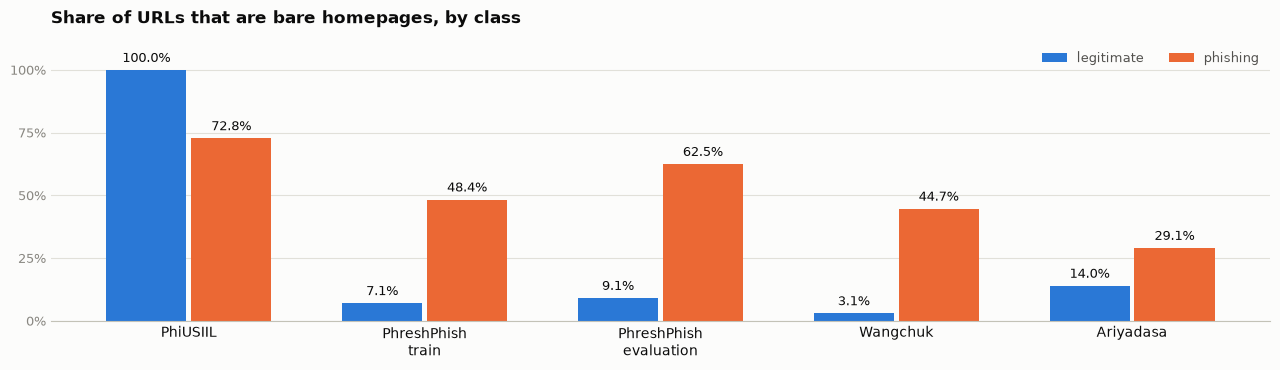

In [22]:
chart = pd.concat([
    phi_prof.assign(source="PhiUSIIL"),
    profiles["train"].assign(source="PhreshPhish train"),
    profiles["eval"].assign(source="PhreshPhish evaluation"),
    D.profile(wang.frames["final"]).assign(source="Wangchuk"),
    D.profile(ari.frames["final"]).assign(source="Ariyadasa"),
], ignore_index=True)
D.plot_share_bars(chart, "is_bare_homepage", "Share of URLs that are bare homepages, by class",
                  D.FIGURES_DIR / "01_bare_homepage_share.png");

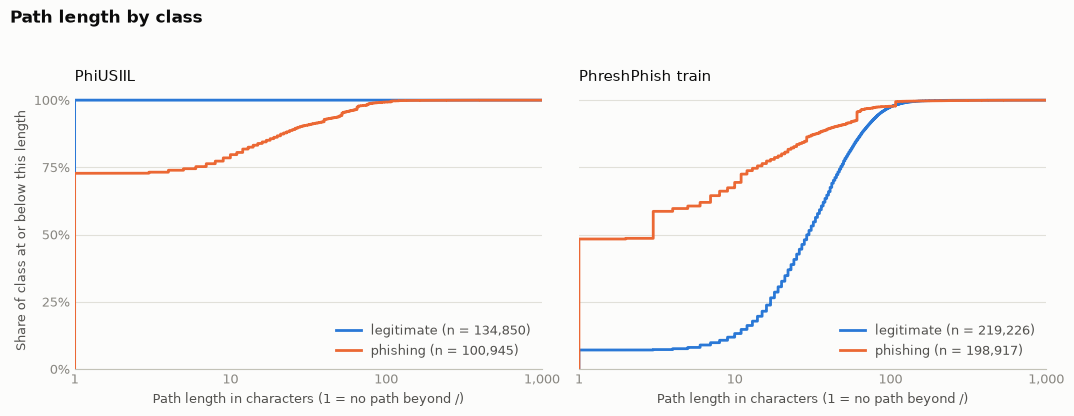

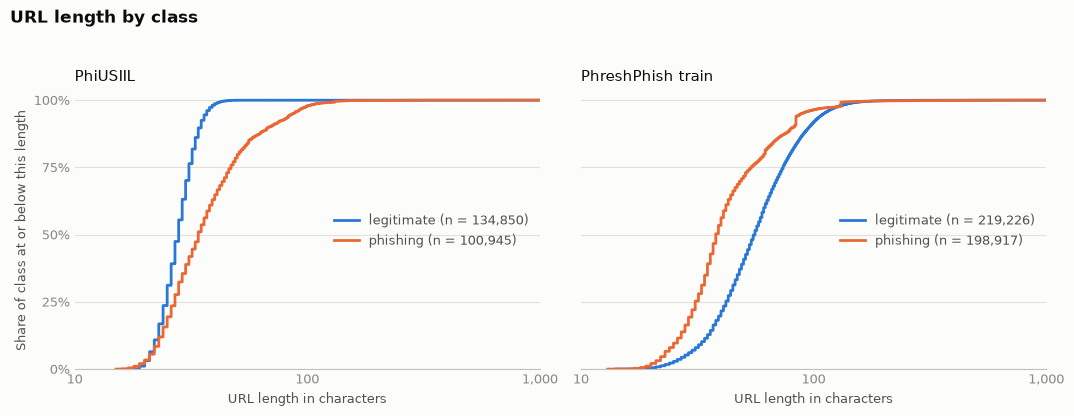

In [23]:
two = chart[chart["source"].isin(["PhiUSIIL", "PhreshPhish train"])]
D.plot_length_ecdf(two, "path_len", "Path length by class", "Path length in characters (1 = no path beyond /)",
                   D.FIGURES_DIR / "01_path_length_by_class.png", xmin=1);
D.plot_length_ecdf(two, "url_len", "URL length by class", "URL length in characters",
                   D.FIGURES_DIR / "01_url_length_by_class.png", xmin=10, legend_loc="center right");

**Reading the charts.** In the bar chart, PhiUSIIL's legitimate class is 100% bare homepages; in every other dataset legitimate URLs are mostly pages with paths, and it is the *phishing* class that is more often a bare homepage. In the path-length chart, each curve is the share of a class at or below a given length: PhiUSIIL's legitimate curve is a single vertical step, because every one of its legitimate URLs has the same (empty) path.

## 9. Conclusion

Read from the saved files:

In [24]:
m = D.load_manifest()
da, wa, aa = (A.read_json(A.REPORTS_DIR / name) for name in
              ("data_audit.json", "secondary_audit.json", "secondary_audit_ariyadasa.json"))
f = m["files"]
display(Markdown(
    f"- **Training (fit):** {f['phreshphish_train']['rows']:,} URLs, {da['splits']['train']['date_min']} to {da['splits']['train']['date_max']}.\n"
    f"- **Validation:** {f['phreshphish_val']['rows']:,} URLs, {da['splits']['val']['date_min']} to {da['splits']['val']['date_max']}; "
    f"used only for calibration and thresholds.\n"
    f"- **Later-in-time test:** {f['phreshphish_eval']['rows']:,} pinned rows of the PhreshPhish test split, "
    f"{da['splits']['eval_sample']['date_min']} to {da['splits']['eval_sample']['date_max']}.\n"
    f"- **Gate 1: {'passed' if da['gate1']['passed'] else 'FAILED'}.** No date overlap; highest single-feature AUC "
    f"{da['gate1']['highest_single_feature_auc']['direction_free']:.3f}.\n"
    f"- **Wangchuk (unseen secondary): Gate 2 {'passed' if wa['gate2']['passed'] else 'FAILED'}**, {f['wangchuk']['rows']:,} URLs "
    f"({f['wangchuk']['legitimate']:,} presumed benign, {f['wangchuk']['phishing']:,} phishing).\n"
    f"- **Ariyadasa (second external check): Gate 2 {'passed' if aa['gate2']['passed'] else 'FAILED'}**, {f['ariyadasa']['rows']:,} URLs "
    f"({f['ariyadasa']['legitimate']:,} presumed benign, {f['ariyadasa']['phishing']:,} phishing).\n"
    f"- **PhiUSIIL baseline split:** {f['phiusiil_train']['rows']:,} / {f['phiusiil_val']['rows']:,} / {f['phiusiil_test']['rows']:,}.\n"
    f"- **One-sided feature scan:** only the query features, and none in the main track."
))

- **Training (fit):** 418,143 URLs, 2024-07-02 to 2025-07-28.
- **Validation:** 76,009 URLs, 2025-07-29 to 2025-09-07; used only for calibration and thresholds.
- **Later-in-time test:** 50,000 pinned rows of the PhreshPhish test split, 2025-09-08 to 2025-12-16.
- **Gate 1: passed.** No date overlap; highest single-feature AUC 0.808.
- **Wangchuk (unseen secondary): Gate 2 passed**, 98,085 URLs (59,162 presumed benign, 38,923 phishing).
- **Ariyadasa (second external check): Gate 2 passed**, 76,169 URLs (48,477 presumed benign, 27,692 phishing).
- **PhiUSIIL baseline split:** 162,884 / 34,904 / 34,904.
- **One-sided feature scan:** only the query features, and none in the main track.

Known limits of this data, carried into the results:

- **Calibrated scores are not real-world probabilities.** No legitimate rows exist for November 2024 to April 2025, and the class mix of every set is set by collection, not by how often phishing occurs.
- **Both external datasets are older than the training data.** They test a different source, not the future. Only the PhreshPhish evaluation sample is later in time.
- **"Presumed benign" is not verified benign**, and Wangchuk's covers only 547 domains.
- **Registered domains repeat** between training and every evaluation set, mostly hosting platforms. Results are split by seen and unseen domain.

Next: `02_lgbm.ipynb` trains LightGBM on `phreshphish_train.parquet`. No evaluation set is opened again until `04_evaluation.ipynb`.